# Basis and coefficient comparison

Three estimators of a coefficient function that vanishes on part of its domain, run over nine
designs. The model is the same for all three,

$$y_i = \int_0^1 x_i(t)\,\psi(t)\,\mathrm{d}t + \varepsilon_i, \qquad
\varepsilon_i \sim N(0, \sigma^2),$$

and the difference is the way the estimator behaves when it comes to zeroing regions. The `truncFLR` package estimates the endpoint of a single interval, either by method A (simultaneous inference, more computationally intensive) or method B (iterative inference, an "initial check" before running the heavier method A). `fdaSP` lets the informative region be a disjoint union of intervals, and induces sparsity by an "overlapping group lasso". Rather than scanning for a boundary, it "switches off" coefficients of basis functions in less informative regions.

We vary both the bases we are working with and the coefficient functions we are estimating in this notebook. 
- Bases: Trigonometric, Legendre, B-spline;
- Coefficient functions: Step function (sharp increase), smooth rise at a boundary, two bumps with a null region in between.

We expect that `truncFLR` will struggle with the last coefficient function, however I decided to include it for comparison.

The machinery is in `bench/design.py` and `bench/study.py`, and the study itself is cached
under `artifacts/`, so nothing here refits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from bench import design, study, style
from fdaSP import SBC

style.use(plt)
pd.set_option("display.width", 200)

grid = np.linspace(0, 1, study.CONFIG["n_grid"])
COLOUR, TRUTH = style.METHOD_COLOUR, style.INK
BASIS_LINE = {"trig": "-", "legendre": "--", "bspline": ":"}
JITTER = np.random.default_rng(0)


def method_legend(fig, methods=study.METHOD_ORDER, truth=True, y=0.0):
    """One legend per figure, at the bottom, in the fixed method order."""
    handles = [plt.Line2D([], [], color=COLOUR[m], lw=1.6, label=m) for m in methods]
    if truth:
        handles.append(plt.Line2D([], [], color=TRUTH, lw=1.7, ls="--", label=r"true $\psi$"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               bbox_to_anchor=(0.5, y), columnspacing=2.0)


print(f"{len(design.BASIS_KINDS)} bases x {len(design.TARGETS)} coefficient functions, "
      f"{study.CONFIG['n_rep']} replications each")
print({k: study.CONFIG[k] for k in
       ("n", "n_grid", "n_basis", "decay", "snr", "n_test", "n_rep")})

3 bases x 3 coefficient functions, 40 replications each
{'n': 200, 'n_grid': 201, 'n_basis': 25, 'decay': 6.0, 'snr': 20.0, 'n_test': 500, 'n_rep': 40}


## The designs

Changing the basis has to change one thing only. Curves are drawn as a random expansion

$$X_i(t) = \sum_{k=1}^{K} c_{ik}\, e_k(t), \qquad c_{ik} \sim N(0, v_k)
\ \text{ independently},$$

in a basis $\{e_k\}$ that is *orthonormal* in $L^2[0,1]$. The covariance operator of $X$ is
then $\sum_k v_k\, e_k \otimes e_k$, and its eigenvalues are exactly the $v_k$, whatever the
basis. Holding $v_k = \exp\{-(k-1)/\text{decay}\}$ fixed — the profile Hall & Hooker's own
Section 4 generates with — and varying only the $e_k$ therefore changes the *directions* the
predictor varies in without touching how fast that variation decays. Difficulty is held
constant; geometry is not.

Orthonormalising fixes the inner product but not the order, and the order is what the variance
profile attaches to, so it has to mean the same thing in all three families. It does not by
default. The Legendre and trigonometric families run upwards from the constant in oscillation,
but a B-spline family runs left to right across the domain, so a decaying variance on it piles
the curves' variation at one end and hands the truncation model an orientation before it has
seen any data. `design.basis` therefore diagonalises the roughness form $\int e_j' e_k'$ inside
each span and orders every family from smoothest to roughest. For the trigonometric family that
recovers the frequency ordering it already had; for the B-spline family it replaces position by
smoothness. This was not a preference: on the design it replaced, method B's own $\lambda$
selection could be undefined at *every* candidate — $S_Y$ having no interior minimum for any of
them, so the step-6 variance is a Taylor expansion about a minimum that does not exist — and
`tests/test_bench.py` keeps that design to show it.

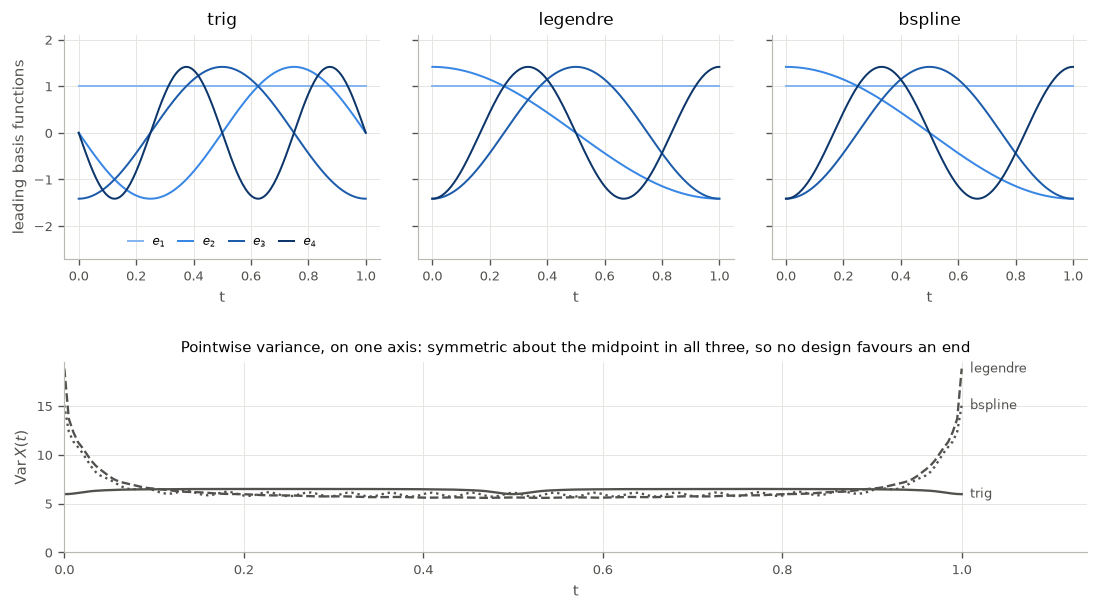

In [2]:
var = design.variance_profile(study.CONFIG["n_basis"], study.CONFIG["decay"])

fig = plt.figure(figsize=(11, 5.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.85], hspace=0.5, wspace=0.12)
top = [fig.add_subplot(gs[0, j]) for j in range(3)]
for j, kind in enumerate(design.BASIS_KINDS):
    Psi = design.basis(grid, kind, study.CONFIG["n_basis"])
    for k, shade in enumerate(style.ordinal(4)):
        top[j].plot(grid, Psi[k], lw=1.2, color=shade, label=f"$e_{{{k + 1}}}$")
    top[j].set_title(kind)
    top[j].set_xlabel("t")
    top[j].set_ylim(-2.7, 2.1)
top[0].set_ylabel("leading basis functions")
for a in top[1:]:
    a.tick_params(labelleft=False)
top[0].legend(ncol=4, loc="lower center", fontsize=7, columnspacing=1.1, handlelength=1.3)

bottom = fig.add_subplot(gs[1, :])
for kind in design.BASIS_KINDS:
    v = design.pointwise_variance(design.basis(grid, kind, study.CONFIG["n_basis"]), var)
    bottom.plot(grid, v, color=style.MUTED, ls=BASIS_LINE[kind], lw=1.4)
    bottom.annotate(kind, (1.0, v[-1]), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8, color=style.MUTED)
bottom.set_xlim(0, 1.14); bottom.set_ylim(0, None)
bottom.set_xlabel("t"); bottom.set_ylabel(r"$\mathrm{Var}\,X(t)$")
bottom.set_title("Pointwise variance, on one axis: symmetric about the midpoint in all three,"
                 " so no design favours an end", fontsize=9)
plt.show()

In [3]:
w = design.quad_weights(grid)
rows = []
for seed, kind in enumerate(design.BASIS_KINDS):
    Psi = design.basis(grid, kind, study.CONFIG["n_basis"])
    emp = design.spectrum(design.sample_curves(20000, Psi, var, rng=seed), grid, k=5)
    v = design.pointwise_variance(Psi, var)
    half = grid <= 0.5
    rows.append({"basis": kind, **{f"tau_{k + 1}": emp[k] for k in range(5)},
                 "var left/right": (w[half] @ v[half]) / (w[~half] @ v[~half])})
print("empirical eigenvalues of the covariance operator, over 20000 curves")
print(pd.DataFrame(rows).set_index("basis").round(4).to_string())
print("prescribed:  " + "  ".join(f"{x:.4f}" for x in var[:5]))

empirical eigenvalues of the covariance operator, over 20000 curves
           tau_1   tau_2   tau_3   tau_4   tau_5  var left/right
basis                                                           
trig      0.9986  0.8584  0.7304  0.5978  0.5217          1.0093
legendre  1.0007  0.8402  0.7157  0.6092  0.5105          1.0088
bspline   0.9800  0.8486  0.7092  0.6063  0.5157          1.0096
prescribed:  1.0000  0.8465  0.7165  0.6065  0.5134


The empirical eigenvalues agree with the prescribed $v_k$ in every basis, and no design puts
more than a percent more variation in one half of the domain than in the other. The three rows
of everything below are therefore comparable: an integrated squared error means the same thing
in each.

## The coefficient functions

$\psi_{\text{step}}(t) = \mathbb{1}\{t \ge 0.6\}$ is a jump, the sharpest boundary the
truncation model can be asked to find. $\psi_{\text{cdf}}$ is zero until $0.8$ and then the
$\mathrm{Beta}(2,2)$ distribution function rescaled to $[0.8, 1]$, rising smoothly to one; it
leaves the axis with zero derivative, which is the harder of the two boundary types in Hall &
Hooker's Section 4. Both are supported on a single window $[u, 1]$, so `truncFLR`'s model is
correct for them, given the right orientation.

$\psi_{\text{multi}}$ is two raised-cosine bumps of *opposite* sign on $[0.1, 0.3]$ and
$[0.55, 0.8]$. Its null set is three disjoint intervals and no single window carries the
signal, in either orientation, so the truncation model is misspecified whatever it is told.
The signs are opposite so that an estimator spanning the gap rather than zeroing it cancels
signal against signal, rather than merely picking up a little bias.

Errors are reported *relative*, divided by $\int \psi^2$, so that $1.0$ is the error of the
estimate that gives up and returns zero and the three targets sit on one scale.

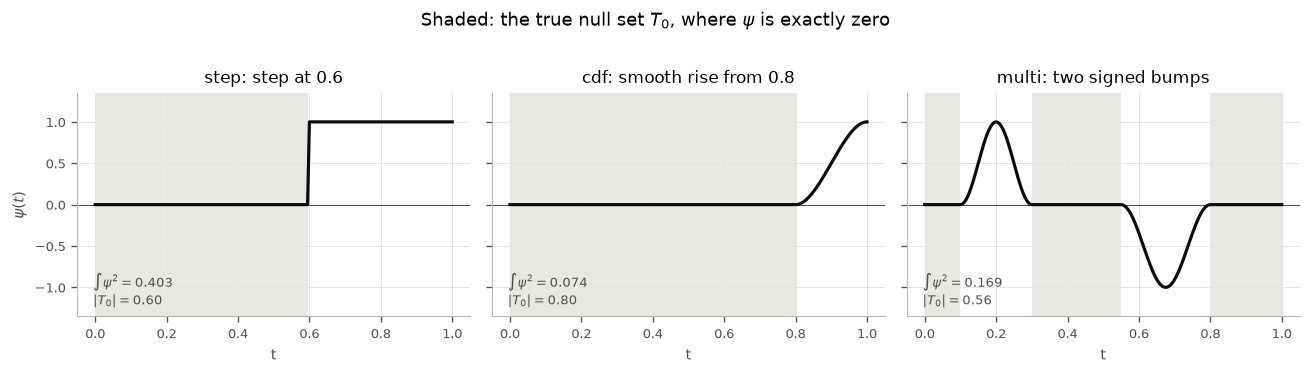

target    int psi^2  |T0| grid        window  null regions
step         0.4025       0.60    (0.6, 1.0)             1
cdf          0.0743       0.80    (0.8, 1.0)             1
multi        0.1688       0.56          none             3


In [4]:
w = design.quad_weights(grid)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.0), sharey=True)
for a, (name, spec) in zip(ax, design.TARGETS.items()):
    psi, null = spec["fn"](grid), spec["null"](grid)
    for lo, hi in SBC.find_regions(null, grid):
        a.axvspan(lo, hi, color=style.BAND, alpha=0.6, lw=0)
    a.axhline(0, color=style.MUTED, lw=0.6)
    a.plot(grid, psi, color=TRUTH, lw=1.9)
    a.set_title(f"{name}: {spec['label']}")
    a.set_xlabel("t")
    a.annotate(rf"$\int\psi^2={np.trapezoid(psi ** 2, grid):.3f}$"
               "\n" rf"$|T_0|={w[null].sum():.2f}$",
               (0.04, 0.05), xycoords="axes fraction", fontsize=8, color=style.MUTED)
ax[0].set_ylabel(r"$\psi(t)$")
ax[0].set_ylim(-1.35, 1.35)
fig.suptitle(r"Shaded: the true null set $T_0$, where $\psi$ is exactly zero", y=1.02)
plt.tight_layout(); plt.show()

print(f"{'target':8}{'int psi^2':>11}{'|T0| grid':>11}{'window':>14}{'null regions':>14}")
for name, spec in design.TARGETS.items():
    psi, null = spec["fn"](grid), spec["null"](grid)
    win = "none" if spec["window"] is None else str(spec["window"])
    print(f"{name:8}{np.trapezoid(psi ** 2, grid):11.4f}{w[null].sum():11.2f}{win:>14}"
          f"{len(SBC.find_regions(null, grid)):>14}")

## What a design can and cannot show

$X$ lives in the span of its own basis, so the response depends on $\psi$ only through its
projection $P\psi$ onto that span. The remainder $\psi - P\psi$ never reaches $y$, and no
amount of data recovers it. The table below is $\int (\psi - P\psi)^2 / \int \psi^2$, the
fraction of each target that its design simply cannot show.

This is not a floor on the realised error, and it is worth being precise about why. An estimate
is written in the *estimator's* basis, not the design's — a B-spline expansion for all three
methods here — and where that basis happens to suit $\psi$ it supplies the missing part for
free. What the gap measures is how much of the answer is prior information rather than
evidence. The trigonometric design is the interesting case: it spans only periodic functions,
so it cannot represent a $\psi$ with $\psi(0) \ne \psi(1)$, which both the step and the
distribution function are.

fraction of int psi^2 lying outside the span of the curves
         trig  legendre  bspline
step   0.0204    0.0152   0.0128
cdf    0.0568    0.0000   0.0000
multi  0.0001    0.0007   0.0003


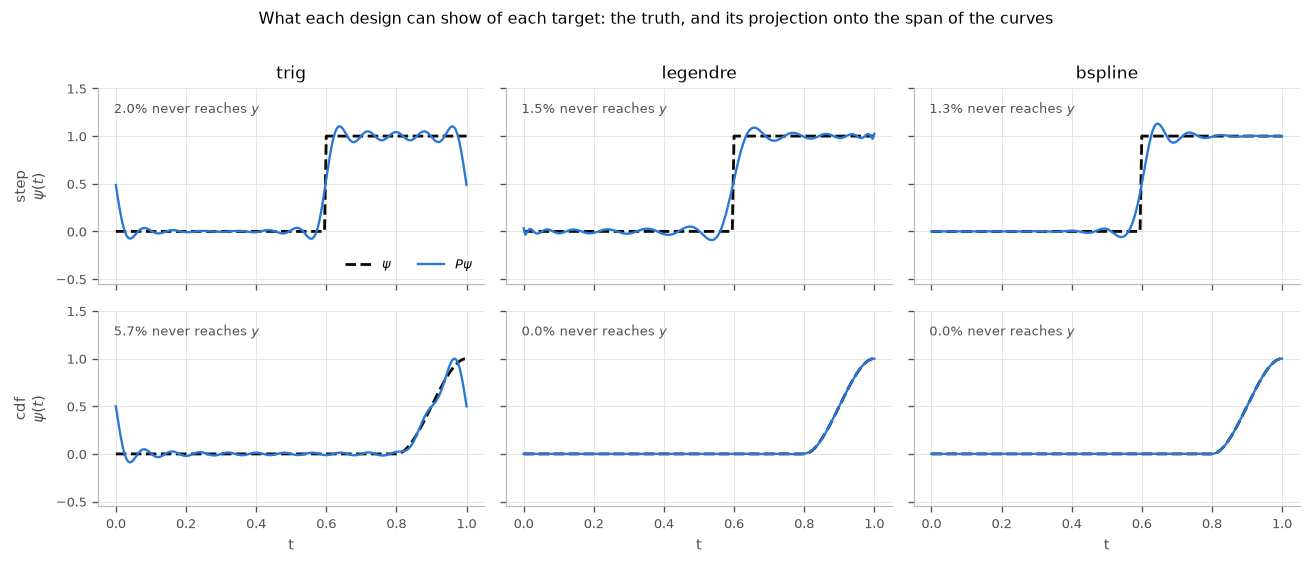

In [5]:
gap = pd.DataFrame(
    {kind: {name: design.projection_gap(spec["fn"](grid),
                                        design.basis(grid, kind, study.CONFIG["n_basis"]),
                                        grid) / np.trapezoid(spec["fn"](grid) ** 2, grid)
            for name, spec in design.TARGETS.items()}
     for kind in design.BASIS_KINDS})
print("fraction of int psi^2 lying outside the span of the curves")
print(gap.round(4).to_string())

fig, ax = plt.subplots(2, 3, figsize=(11, 4.6), sharex=True, sharey="row")
for i, target in enumerate(["step", "cdf"]):
    psi = design.TARGETS[target]["fn"](grid)
    for j, kind in enumerate(design.BASIS_KINDS):
        a = ax[i, j]
        Psi = design.basis(grid, kind, study.CONFIG["n_basis"])
        _, proj = design.project(psi, Psi, grid)
        a.plot(grid, psi, color=TRUTH, ls="--", lw=1.7, label=r"$\psi$")
        a.plot(grid, proj, color=style.CATEGORICAL[0], lw=1.4, label=r"$P\psi$")
        a.annotate(f"{gap.loc[target, kind]:.1%} never reaches $y$",
                   (0.04, 0.87), xycoords="axes fraction", fontsize=8, color=style.MUTED)
        a.set_ylim(-0.55, 1.5)
        if i == 0:
            a.set_title(kind)
        else:
            a.set_xlabel("t")
        if j == 0:
            a.set_ylabel(f"{target}\n" + r"$\psi(t)$")
ax[0, 0].legend(loc="lower right", ncol=2, fontsize=8)
fig.suptitle("What each design can show of each target: the truth, and its projection onto "
             "the span of the curves", fontsize=9.5, y=1.01)
plt.tight_layout(); plt.show()

## What each method is told

The truncation model has to be told which end of the domain carries the signal: `HH.fit` looks
for a window $[0, \theta]$ and `HH.fit_mirror` for a window $[u, 1]$. Handing it the
orientation matching the truth would be information the group lasso is never given, so **both
orientations are fitted and the one with the smaller step-7 BIC is kept**. How often that
agrees with the truth is a result in its own right, below.

Tuning is separated from estimation. Every method is run under the rule its own paper
prescribes — section 3.2 for methods A and B, ten-fold cross-validation for the group lasso,
BIC over components for the untruncated FPCA pilot carried along as the no-sparsity baseline —
and again at the $\lambda$ on the *same grid* that minimises the realised error. The second is
not an estimator. It is an upper bound on what any selection rule could have delivered from
that path, so the gap between the two separates the cost of the rule from the cost of the
estimator. That turns out to matter more than anything else here.

A single replication of each cell first, before the distributions.

14472 rows cached at artifacts/basis_target_curves.csv


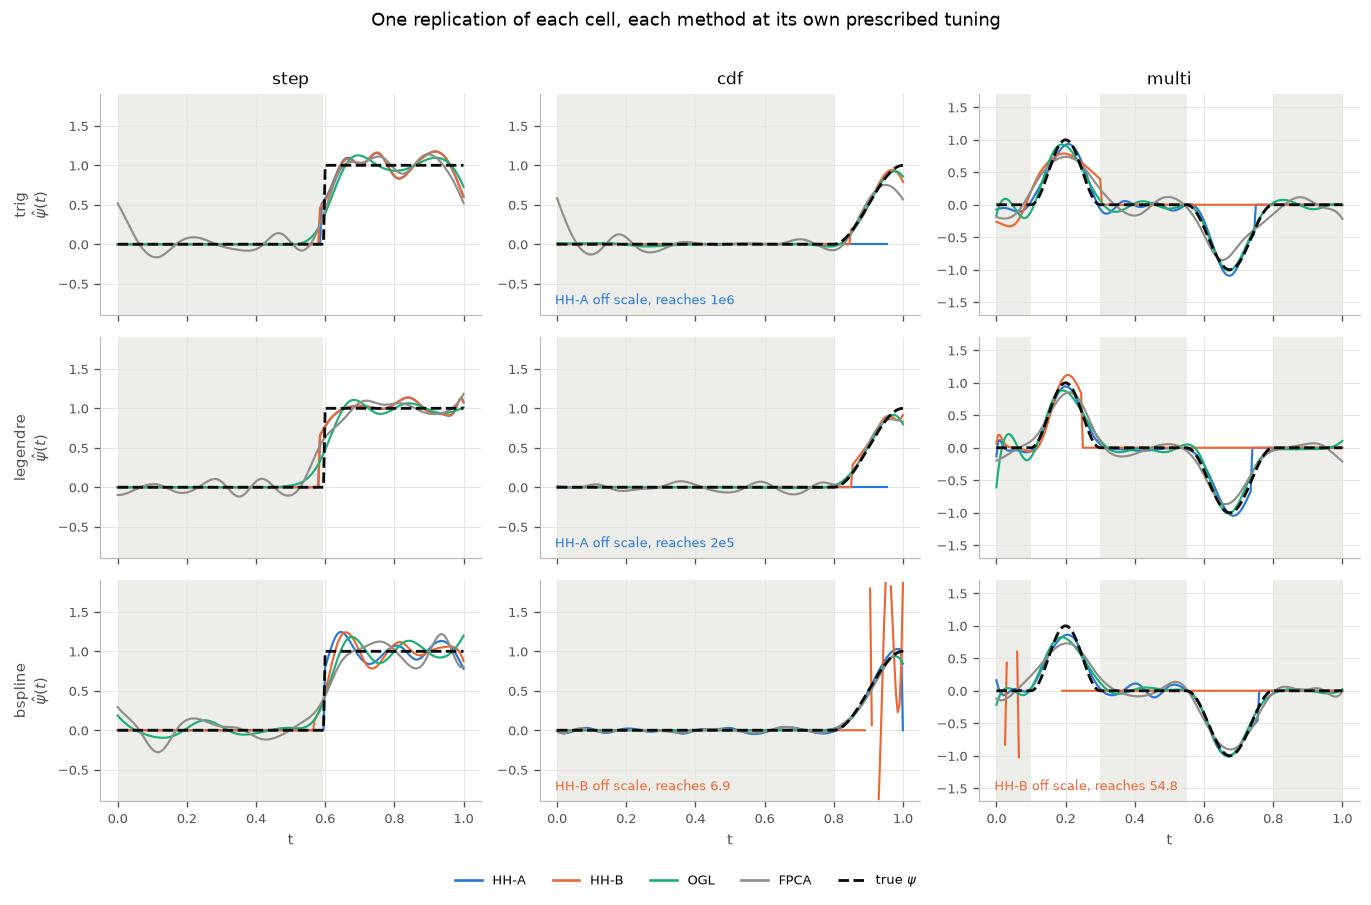

In [6]:
curves = study.cached_curves()
print(f"{len(curves)} rows cached at artifacts/{study.CURVES_ARTIFACT}")

SHOW = [("HH-A", "paper"), ("HH-B", "paper"), ("OGL", "cv"), ("FPCA", "bic")]
YLIM = {"step": (-0.9, 1.9), "cdf": (-0.9, 1.9), "multi": (-1.7, 1.7)}

fig, ax = plt.subplots(3, 3, figsize=(11.5, 7.4), sharex=True)
for i, kind in enumerate(design.BASIS_KINDS):
    for j, target in enumerate(design.TARGETS):
        a = ax[i, j]
        lo, hi = YLIM[target]
        for left, right in SBC.find_regions(design.TARGETS[target]["null"](grid), grid):
            a.axvspan(left, right, color=style.BAND, alpha=0.45, lw=0)
        offscale = []
        for method, tuning in SHOW:
            sel = curves.query("basis == @kind and target == @target "
                               "and method == @method and tuning == @tuning")
            shown, worst = style.clip_to(sel["beta"].to_numpy(), lo, hi)
            a.plot(sel["t"], shown, color=COLOUR[method], lw=1.3)
            if worst is not None:
                offscale.append((method, worst))
        a.plot(grid, design.TARGETS[target]["fn"](grid), color=TRUTH, ls="--", lw=1.7,
               zorder=5)
        a.set_ylim(lo, hi)
        for k, (method, worst) in enumerate(offscale):
            a.annotate(f"{method} off scale, reaches {style.fmt(worst)}",
                       (0.04, 0.05 + 0.11 * k), xycoords="axes fraction",
                       fontsize=7.5, color=COLOUR[method])
        if i == 0:
            a.set_title(target)
        if j == 0:
            a.set_ylabel(f"{kind}\n" + r"$\hat\psi(t)$")
        if i == 2:
            a.set_xlabel("t")
fig.suptitle("One replication of each cell, each method at its own prescribed tuning",
             y=0.995)
method_legend(fig, y=-0.005)
plt.tight_layout(rect=(0, 0.035, 1, 0.985)); plt.show()

The shape of the answer is already visible. Down the `step` and `cdf` columns the truncation
methods track $\psi$ where they get the orientation right and return something near zero when
they do not, and method A's `cdf` fits leave the frame entirely in two of the three rows,
reaching $\pm 10^6$ on the trigonometric design. Down the `multi` column no
truncation is correct, and both methods keep one bump and pay for the other. The group lasso
follows $\psi$ in every panel but does not sit *on* zero in the shaded null regions:
cross-validation has switched no group off.

The forty-replication study follows.

In [7]:
df = study.cached_study()
prescribed = df[df["tuning"].isin(study.PRESCRIBED) & df["bic_pick"]]
print(f"{len(df)} rows cached at artifacts/{study.ARTIFACT}; "
      f"{int(df['lam_failed'].sum())} selection-rule fallbacks fired")


def cell_table(frame, metric, fmt="{:.4g}"):
    """Median of `metric` by method, one row per cell."""
    out = frame.pivot_table(index=["basis", "target"], columns="method", values=metric,
                            aggfunc="median")
    return out[[c for c in study.METHOD_ORDER if c in out.columns]].map(fmt.format)


print()
print("median relative ISE, each method at its own prescribed tuning")
print(cell_table(prescribed, "rise").to_string())

4320 rows cached at artifacts/basis_target_study.csv; 0 selection-rule fallbacks fired

median relative ISE, each method at its own prescribed tuning
method                HH-A      HH-B       OGL     FPCA
basis    target                                        
bspline  cdf       0.05968     1.784   0.00493  0.01884
         multi      0.0454     1.013   0.03156  0.08663
         step      0.02364    0.0289   0.02855  0.04346
legendre cdf     4.624e+09  0.007679  0.004245  0.01557
         multi     0.04026    0.6362   0.03135  0.09087
         step      0.02048   0.02708   0.02924  0.04095
trig     cdf     2.711e+11   0.01955  0.005846   0.1625
         multi     0.04422    0.6391   0.03977  0.09631
         step      0.02654    0.0312   0.03056  0.06464


## Recovering the coefficient function

Four readings, in order of how much they matter.

**Neither model wins outright, and the split is by target rather than by basis.** Method A has
the lowest median error on all three `step` cells; the group lasso on all three `cdf` cells and
on two of the three `multi` cells. Changing the basis moves the numbers and not the ordering:
the result on Hall & Hooker's own trigonometric design is the result on the group lasso's own
B-spline design and on the Legendre design belonging to neither. What decides is the shape of
$\psi$, not what the curves are made of.

**The truncation model earns its keep where its assumption is sharpest.** `step` is a jump at a
single point, and there method A beats a penalty that is never told a null set exists at all,
on 75 to 88 per cent of paired replications. On `cdf` — the same single-window model with a
smooth boundary instead — it loses, by ten orders of magnitude in two of the three cells.

**Method A does not merely lose the `cdf` column, it detonates in two of its three cells**, at
the median rather than in the tail, and on 33 and 40 of 40 replications. Method B does
something similar on the B-spline design, landing above 1 on `cdf` and `multi` — worse than
returning zero. Neither is noise: both are the failure Hall & Hooker's Section 3.2 warns about,
and both are diagnosable at fit time. They are unpicked below.

**The untruncated FPCA pilot, which assumes no null set at all, beats method B in four of the
nine cells.** Assuming a null set and locating it badly is worse than not assuming one.

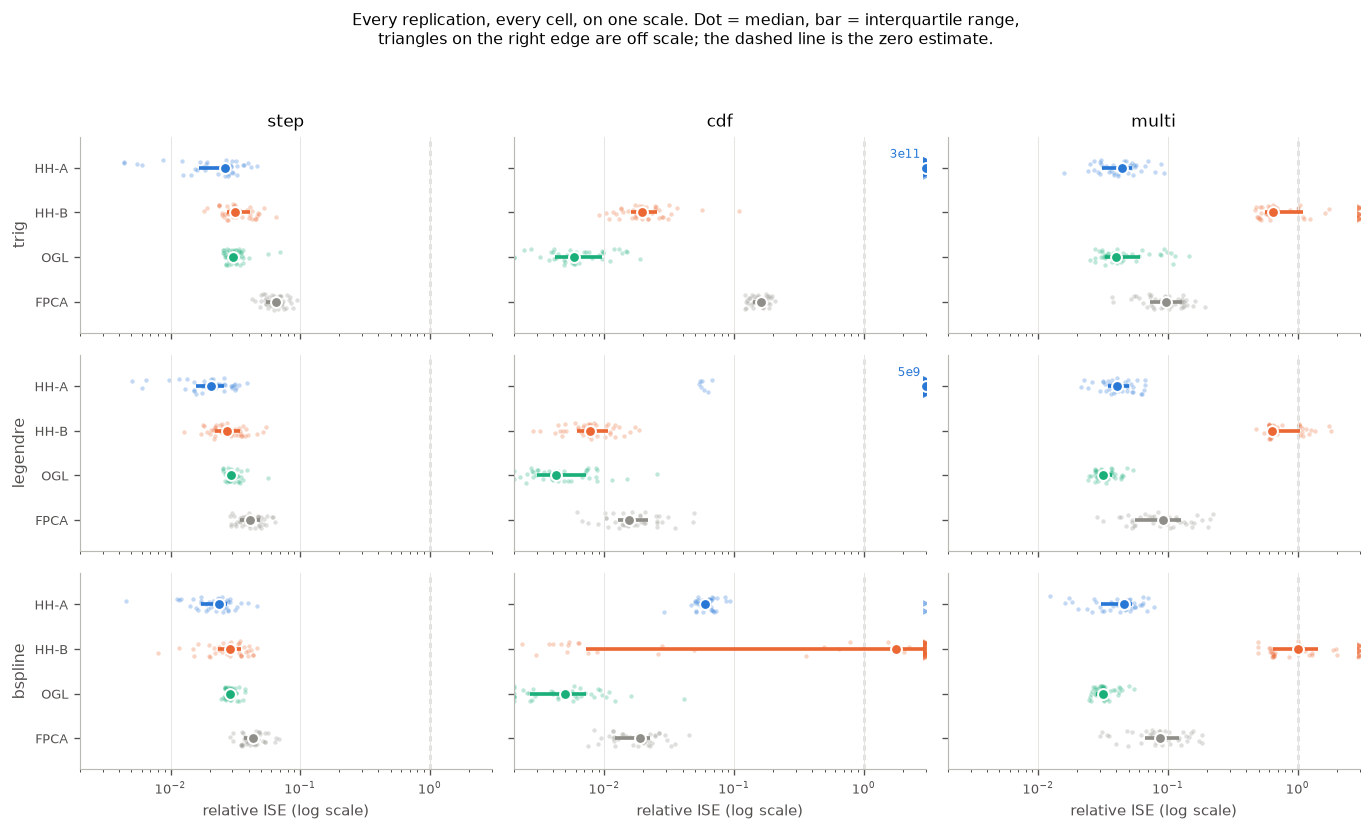

In [8]:
XLO, XHI = 2e-3, 3.0


def dot_panel(a, cell, methods, metric="rise", lo=XLO, hi=XHI):
    """One panel: a jittered strip of every replication, an interquartile bar and a median
    dot, one row per method. Values off the right-hand end are drawn on the edge as
    triangles, and an off-scale median is written next to it."""
    for row, method in enumerate(methods):
        y = len(methods) - 1 - row
        v = cell.loc[cell["method"] == method, metric].to_numpy()
        v = v[np.isfinite(v)]
        if not v.size:
            continue
        inside, outside = np.clip(v, lo, hi), v > hi
        a.scatter(inside[~outside], y + JITTER.uniform(-0.18, 0.18, (~outside).sum()),
                  s=7, color=COLOUR[method], alpha=0.28, lw=0)
        if outside.any():
            a.scatter(np.full(outside.sum(), hi),
                      y + JITTER.uniform(-0.18, 0.18, outside.sum()),
                      s=16, marker=">", color=COLOUR[method], alpha=0.55, lw=0)
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        a.plot([np.clip(q1, lo, hi), np.clip(q3, lo, hi)], [y, y],
               color=COLOUR[method], lw=2.2, solid_capstyle="butt", zorder=3)
        a.plot([np.clip(med, lo, hi)], [y], marker="o", ms=6.5, color=COLOUR[method],
               mec="white", mew=1.2, zorder=4)
        if med > hi:
            a.annotate(style.fmt(med), (hi, y), xytext=(-3, 6),
                       textcoords="offset points", ha="right", fontsize=7,
                       color=COLOUR[method])
    a.set_xscale("log")
    a.set_xlim(lo, hi)
    a.set_ylim(-0.7, len(methods) - 0.3)
    a.set_yticks(range(len(methods)))
    a.set_yticklabels(list(reversed(methods)))
    a.axvline(1.0, color=style.MUTED, lw=0.8, ls=(0, (4, 3)), zorder=1)
    a.grid(axis="y", visible=False)


fig, ax = plt.subplots(3, 3, figsize=(11.5, 6.6), sharex=True, sharey=True)
for i, kind in enumerate(design.BASIS_KINDS):
    for j, target in enumerate(design.TARGETS):
        a = ax[i, j]
        dot_panel(a, prescribed.query("basis == @kind and target == @target"),
                  study.METHOD_ORDER)
        if i == 0:
            a.set_title(target)
        if j == 0:
            a.set_ylabel(kind, fontsize=9.5)
        else:
            a.tick_params(labelleft=False)
        if i == 2:
            a.set_xlabel("relative ISE (log scale)")
fig.suptitle("Every replication, every cell, on one scale. Dot = median, bar = interquartile "
             "range,\ntriangles on the right edge are off scale; the dashed line is the "
             "zero estimate.", fontsize=9.5, y=1.04)
plt.tight_layout(); plt.show()

In [9]:
print("median relative ISE on the true null set T0 -- how well each respects the zero")
print(cell_table(prescribed, "rise_T0").to_string())
print()
print("median relative ISE on the support T1 -- how well each fits the signal")
print(cell_table(prescribed, "rise_T1").to_string())
print()
print("median relative ISE against P psi, the part of psi the curves can show")
print(cell_table(prescribed, "rise_id").to_string())

median relative ISE on the true null set T0 -- how well each respects the zero
method               HH-A     HH-B        OGL     FPCA
basis    target                                       
bspline  cdf      0.01683        0  0.0006921  0.01396
         multi   0.007941  0.03503    0.01465  0.03328
         step     0.01278  0.01699   0.009047  0.02386
legendre cdf            0        0   0.000402  0.01248
         multi   0.009478  0.02373    0.01487  0.03005
         step     0.01055  0.01715    0.01048  0.02273
trig     cdf            0        0  0.0008794  0.08716
         multi   0.009812   0.0162    0.02559  0.03631
         step    0.009266  0.01764   0.009867  0.03293

median relative ISE on the support T1 -- how well each fits the signal
method                HH-A      HH-B       OGL      FPCA
basis    target                                         
bspline  cdf       0.04059     1.784  0.004176  0.002717
         multi     0.03349    0.9881   0.01623   0.05665
         step   

Both of the first two tables are against the true $\psi$. Against $P\psi$ they change only
where the projection gap is not negligible — the `step` column and the trigonometric `cdf`
cell — and they change in opposite directions.

On `step` every method looks *better* against $P\psi$, 0.01479 against 0.02364 for method A,
because part of what the first table charged it for is the Gibbs remainder of a jump, which no
estimator on this design could have recovered from these curves. On the trigonometric `cdf`
cell method B and the group lasso look substantially *worse*: 0.05605 against 0.01955, and
0.04684 against 0.005846. Both fit a B-spline expansion, and a B-spline represents a function
that is zero until 0.8 and then rises to one far better than twenty-five periodic functions do,
so a good part of the accuracy in that cell is the estimator's own basis agreeing with the
truth rather than the data saying so. It is the one place here where a good number is not
evidence, and it is worth knowing which cell that is.

## Locating the null set

Relative ISE rewards being close to zero. It does not reward being *exactly* zero, which is
what this literature is about. Two numbers that do: the length of the null set an estimate
actually reports, and the Jaccard overlap of that set with the true one, which is 1 only when
the two coincide and takes no credit for a coefficient that is merely small.

Every estimate here reports an exact null set. The truncation methods report the complement of
their fitted window. The group lasso reports the region no surviving basis group supports,
which `fdaSP.SBC` snaps to exact zeros so the reported support and the reported coefficients
agree. The FPCA pilot reports none, which is why it is here.

Summarising a set into one number throws away where it is, so the picture comes first: for
every grid point, the share of the forty replications in which each method left that point in
the support, against the truth on the top strip of each panel. Pale is a recovered null set.

In [10]:
print("median Jaccard overlap of the estimated null set with the true one")
print(cell_table(prescribed, "null_jaccard", "{:.3f}").to_string())
print()
print("median length of the estimated null set (the true |T0| is 0.60, 0.80 and 0.55)")
print(cell_table(prescribed, "null_measure", "{:.3f}").to_string())

median Jaccard overlap of the estimated null set with the true one
method            HH-A   HH-B    OGL   FPCA
basis    target                            
bspline  cdf     0.000  0.904  0.000  0.000
         multi   0.327  0.521  0.000  0.000
         step    0.983  0.967  0.000  0.000
legendre cdf     0.838  0.947  0.000  0.000
         multi   0.328  0.542  0.000  0.000
         step    0.983  0.967  0.000  0.000
trig     cdf     0.834  0.939  0.000  0.000
         multi   0.327  0.525  0.000  0.000
         step    0.983  0.971  0.000  0.000

median length of the estimated null set (the true |T0| is 0.60, 0.80 and 0.55)
method            HH-A   HH-B    OGL   FPCA
basis    target                            
bspline  cdf     0.003  0.887  0.000  0.000
         multi   0.247  0.780  0.000  0.000
         step    0.588  0.578  0.000  0.000
legendre cdf     0.958  0.847  0.000  0.000
         multi   0.247  0.732  0.000  0.000
         step    0.588  0.578  0.000  0.000
trig     cdf     

In [11]:
ogl = df[df["method"] == "OGL"]
print("the group lasso, by selection rule:")
print(ogl.assign(nothing=ogl["null_measure"] == 0)
      .pivot_table(index="target", columns="tuning",
                   values=["nothing", "null_jaccard", "rise"], aggfunc="median")
      .round(3).to_string())
print()
print("'nothing' is the share of replications that switched no group off at all.")

Phi = SBC.bspline_basis(grid, n_basis=study.CONFIG["ogl_basis"], order=study.CONFIG["order"])
_, groups = SBC.pen_matrices(study.CONFIG["ogl_basis"], order=study.CONFIG["order"])
widths = [float(np.ptp(grid[(Phi[:, g] != 0).any(axis=1)])) for g in groups]
print()
print(f"{len(groups)} penalty groups; the narrowest spans {min(widths):.2f} of the domain, "
      f"against a null gap of {0.55 - 0.30:.2f} in psi_multi")

the group lasso, by selection rule:
       nothing               null_jaccard                 rise              
tuning      cv one_se oracle           cv one_se oracle     cv one_se oracle
target                                                                      
cdf        1.0    0.0    1.0          0.0  0.832    0.0  0.005  0.009  0.004
multi      1.0    1.0    1.0          0.0  0.000    0.0  0.033  0.040  0.029
step       1.0    0.0    1.0          0.0  0.556    0.0  0.029  0.035  0.028

'nothing' is the share of replications that switched no group off at all.

12 penalty groups; the narrowest spans 0.33 of the domain, against a null gap of 0.25 in psi_multi


14472 rows cached at artifacts/basis_target_support.csv


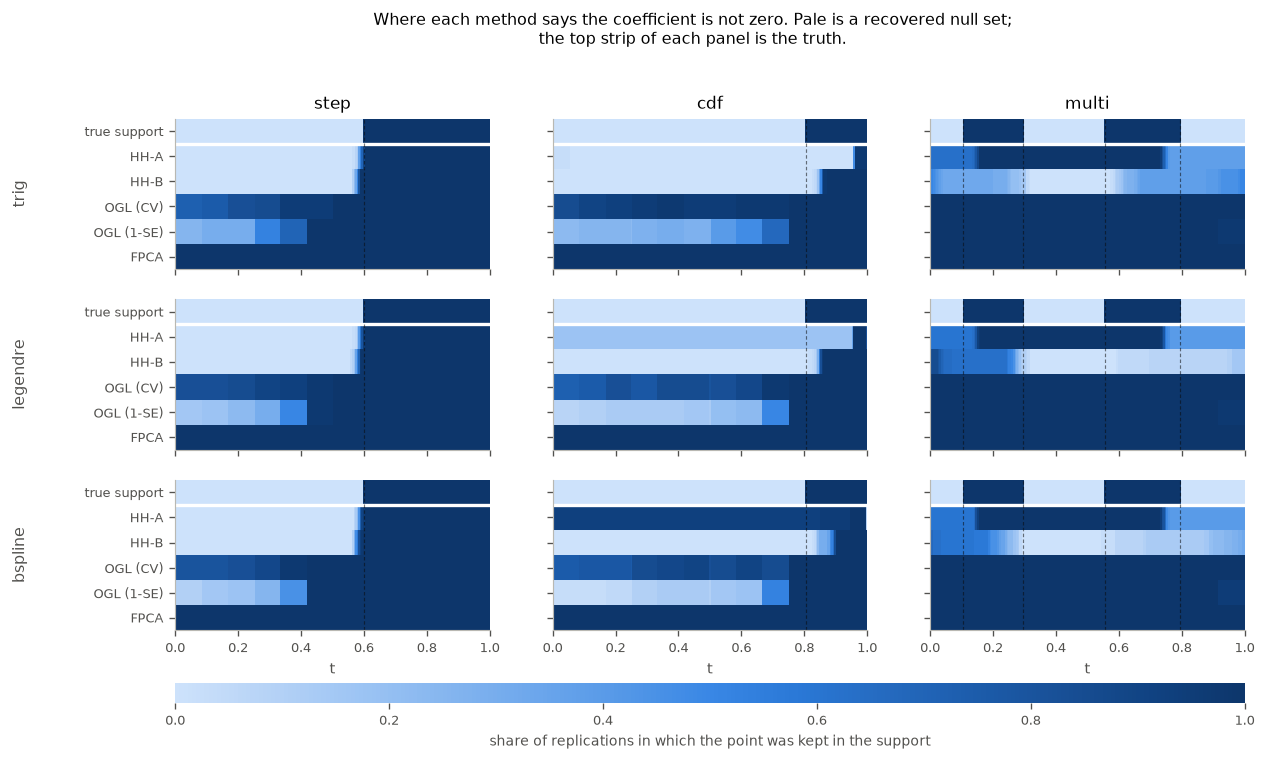

In [12]:
support = study.cached_support()
print(f"{len(support)} rows cached at artifacts/{study.SUPPORT_ARTIFACT}")

STRIP = [("truth", ""), ("HH-A", "paper"), ("HH-B", "paper"), ("OGL", "cv"),
         ("OGL", "one_se"), ("FPCA", "bic")]
STRIP_LABEL = {("truth", ""): "true support", ("OGL", "cv"): "OGL (CV)",
               ("OGL", "one_se"): "OGL (1-SE)"}

fig, ax = plt.subplots(3, 3, figsize=(11.5, 6.4), sharex=True)
for i, kind in enumerate(design.BASIS_KINDS):
    for j, target in enumerate(design.TARGETS):
        a = ax[i, j]
        rows = []
        for method, tuning in STRIP:
            if method == "truth":
                rows.append((~design.TARGETS[target]["null"](grid)).astype(float))
            else:
                sel = support.query("basis == @kind and target == @target "
                                    "and method == @method and tuning == @tuning")
                rows.append(sel.sort_values("t")["in_support"].to_numpy())
        im = a.imshow(np.vstack(rows), aspect="auto", cmap=style.SEQUENTIAL, vmin=0, vmax=1,
                      extent=(0.0, 1.0, len(STRIP), 0.0), interpolation="nearest")
        a.axhline(1.0, color=style.SURFACE, lw=2.0)
        for left, right in SBC.find_regions(~design.TARGETS[target]["null"](grid), grid):
            for edge in (left, right):
                if 0.0 < edge < 1.0:
                    a.axvline(edge, color=style.INK, lw=0.7, ls=(0, (3, 2)), alpha=0.55)
        a.set_yticks(np.arange(len(STRIP)) + 0.5)
        a.grid(False)
        if i == 0:
            a.set_title(target)
        if j == 0:
            a.set_yticklabels([STRIP_LABEL.get(k, k[0]) for k in STRIP], fontsize=7.5)
            a.set_ylabel(kind, fontsize=9.5, labelpad=34)
        else:
            a.tick_params(labelleft=False)
        if i == 2:
            a.set_xlabel("t")
bar = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.045, pad=0.09,
                   aspect=55)
bar.set_label("share of replications in which the point was kept in the support",
              fontsize=8.5, color=style.MUTED)
bar.outline.set_visible(False)
fig.suptitle("Where each method says the coefficient is not zero. Pale is a recovered null "
             "set;\nthe top strip of each panel is the truth.", fontsize=9.5, y=1.02)
plt.show()

Cross-validation never delivers local sparsity. Across all nine cells it returns a null set of
length zero on *every* replication, so its overlap with the truth is zero even where its
relative error is the lowest in the table. This reproduces what `LocSpaFLR_f2s.ipynb` and
`tecator_application.ipynb` found on the paper's own designs and on Tecator, and the reason is
the same: cross-validation targets prediction risk, and an exact zero is worth more for support
recovery than for prediction, so the two optima do not coincide.

The one-standard-error rule does deliver it on the two single-window targets, and cheaply — a
Jaccard overlap of 0.83 on `cdf` and 0.56 on `step`, for a median relative error of 0.009
against cross-validation's 0.005. On `multi` nothing recovers the null set, and the last line
of output above says why: the narrowest penalty group spans a third of the domain, wider than
the 0.25 gap between the two bumps, so no group lies inside the gap and switching any of them
off would cut into a bump. The null set is there; this basis has no group shaped like it.

Against that, both truncation methods return a substantial null set by construction, and where
they identify the window a very accurate one — method A recovers 98 per cent of the step's null
set, method B 90 to 95 per cent of the distribution function's. That is the trade the two
literatures actually represent. Not accuracy, which depends on the target, but whether a null
set is an output at all.

The lengths in the second table are trapezium measures of a grid mask, which charge a half
panel at each boundary; the true $|T_0|$ are 0.60, 0.80 and 0.55.

## Locating the endpoint

For the two single-window targets there is one number to get right, $u$. The truncation model
reports it directly; the group lasso only implies it, as the left edge of the last stretch of
support left standing, and it is read off the same way for both here. The error is reported
*signed*, because truncating early and truncating late are different mistakes.

median signed endpoint error, u_hat - u
method              HH-A     HH-B      OGL     FPCA
basis    target                                    
bspline  cdf     -0.8000  +0.0900  -0.8000  -0.8000
         step    -0.0100  -0.0200  -0.6000  -0.6000
legendre cdf     +0.1600  +0.0500  -0.8000  -0.8000
         step    -0.0100  -0.0200  -0.6000  -0.6000
trig     cdf     +0.1625  +0.0575  -0.8000  -0.8000
         step    -0.0100  -0.0175  -0.6000  -0.6000


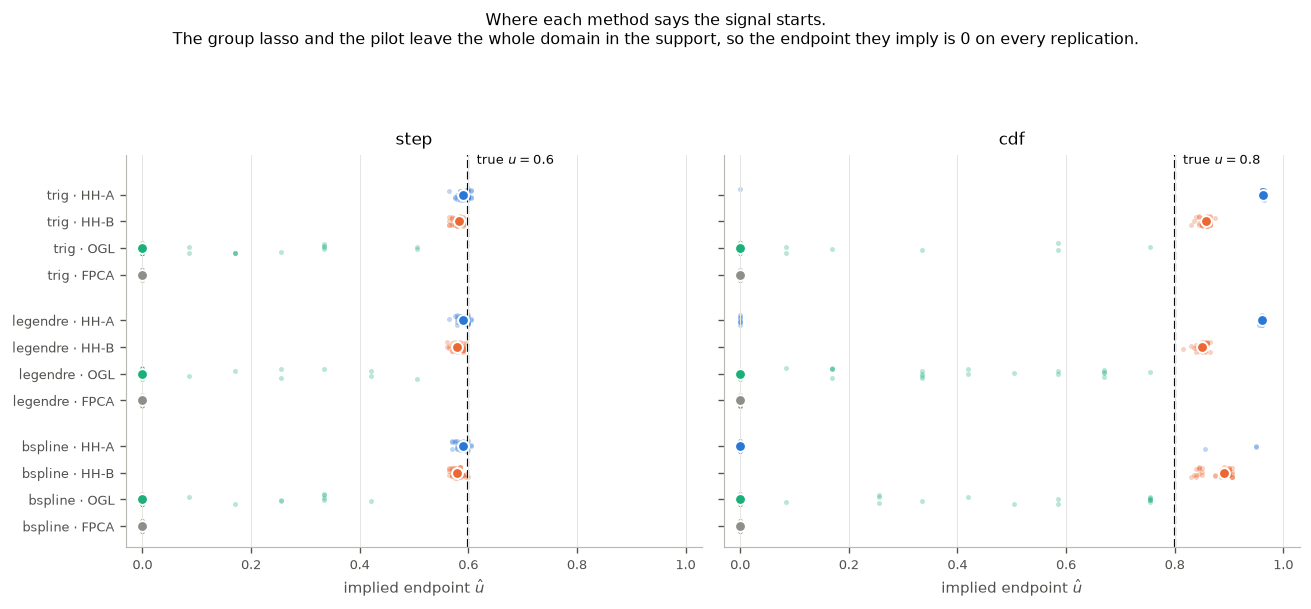

In [13]:
windowed = prescribed[prescribed["target"].isin(["step", "cdf"])]
print("median signed endpoint error, u_hat - u")
print(cell_table(windowed, "u_err", "{:+.4f}").to_string())

positions, ticks, y = [], [], 0.0
for kind in reversed(design.BASIS_KINDS):
    for method in reversed(study.METHOD_ORDER):
        positions.append((kind, method, y))
        ticks.append(f"{kind} · {method}")
        y += 1.0
    y += 0.7

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for a, target in zip(ax, ["step", "cdf"]):
    u = design.TARGETS[target]["window"][0]
    cell = windowed[windowed["target"] == target]
    for kind, method, row in positions:
        v = cell.query("basis == @kind and method == @method")["u_hat"].to_numpy()
        v = v[np.isfinite(v)]
        a.scatter(v, row + JITTER.uniform(-0.2, 0.2, v.size), s=9,
                  color=COLOUR[method], alpha=0.3, lw=0)
        a.plot([np.median(v)], [row], marker="o", ms=6.5, color=COLOUR[method],
               mec="white", mew=1.2, zorder=4)
    a.axvline(u, color=TRUTH, lw=1.3, ls="--", zorder=1)
    a.annotate(f"true $u = {u}$", (u, y - 0.55), xytext=(5, 0),
               textcoords="offset points", fontsize=8, color=TRUTH)
    a.set_xlim(-0.03, 1.03)
    a.set_title(target)
    a.set_xlabel(r"implied endpoint $\hat u$")
    a.grid(axis="y", visible=False)
ax[0].set_yticks([row for _k, _m, row in positions])
ax[0].set_yticklabels(ticks, fontsize=7.5)
ax[0].set_ylim(-0.8, y - 0.2)
fig.suptitle("Where each method says the signal starts.\nThe group lasso and the pilot "
             "leave the whole domain in the support, so the endpoint they imply is 0 on "
             "every replication.", fontsize=9.5, y=1.09)
plt.tight_layout(); plt.show()

The sign is the interesting part, and it is the same in all three bases.

On `step` both truncation methods place the boundary slightly **early** — method A by two grid
spacings, method B by three or four — so both keep a sliver of the null set rather than cutting
into the signal. On `cdf` both are **late**, and by much more: method B by 0.05 to 0.09, method
A by 0.16 wherever it identifies the orientation at all. That is the smooth boundary doing
exactly what one should expect of it. Just past $u = 0.8$ the coefficient is still almost zero,
so nothing in the residuals argues for keeping that stretch, and the estimated window starts
where the signal becomes *visible* rather than where it becomes non-zero. It is a bias rather
than noise, and it is the same bias `HH_vs_SBC.ipynb` saw on a raised-cosine boundary.

The group lasso and the pilot sit at $\hat u = 0$ in every cell, which is what "no boundary
found" looks like when the endpoint has to be read off a support set covering the whole domain.
That is less a competitor here than a reminder that the endpoint is a quantity the penalty does
not estimate.

## Which orientation the data chose

The truncation methods were not told where to look. Both windows were fitted and the step-7
BIC kept one. For `step` and `cdf` there is a right answer, the mirrored $[u, 1]$ fit; for
`multi` there is not, and the column is there to show what an even split looks like.

In [14]:
paper = df[df["tuning"] == "paper"]
picked = paper[paper["bic_pick"]]
print("share of replications where BIC chose the [u, 1] window")
print(picked.assign(right=picked["orientation"] == "right")
      .pivot_table(index=["basis", "target"], columns="method", values="right")
      .round(2).to_string())

both = paper.pivot_table(index=["basis", "target", "rep", "method"], columns="orientation",
                         values="rise")
chose_right = (picked.set_index(["basis", "target", "rep", "method"])["orientation"]
               .reindex(both.index) == "right")
comp = pd.DataFrame({"chosen": np.where(chose_right, both["right"], both["left"]),
                     "best of the two": both.min(axis=1)}, index=both.index)
print()
print("median relative ISE: the orientation BIC chose, against the better of the two")
print(comp.groupby(level=[0, 1, 3]).median().unstack().map("{:.4g}".format).to_string())

share of replications where BIC chose the [u, 1] window
method           HH-A  HH-B
basis    target            
bspline  cdf     0.08  1.00
         multi   0.40  0.32
         step    1.00  1.00
legendre cdf     0.82  1.00
         multi   0.40  0.15
         step    1.00  1.00
trig     cdf     0.98  1.00
         multi   0.38  0.50
         step    1.00  1.00

median relative ISE: the orientation BIC chose, against the better of the two
                    chosen           best of the two          
method                HH-A      HH-B            HH-A      HH-B
basis    target                                               
bspline  cdf       0.05968     1.784         0.05814     1.275
         multi      0.0454     1.013          0.0368     1.006
         step      0.02364    0.0289         0.02364    0.0289
legendre cdf     4.624e+09  0.007679          0.0615  0.007679
         multi     0.04026    0.6362          0.0369    0.6362
         step      0.02048   0.02708         0.02048 

## The rule against the estimator

Every method is now scored twice on the same fits: once at the $\lambda$ its own rule chose,
and once at the $\lambda$ on the same grid that would have minimised the realised error. The
second is unavailable in practice — it uses the truth — but the ratio is exactly what the
selection rule costs. A ratio near 1 says the rule finds what is there; a large one says the
estimator could do far better than its own tuning lets it.

In the figure below, each bar runs from the hollow dot at the best penalty on the grid to the
filled dot at the one the rule chose, so a short bar is a rule that is finding what is there
and a long one is a rule throwing away an estimator that works.

In [15]:
best_lam = (df[df["tuning"] == "oracle"]
            .groupby(["basis", "target", "rep", "method"])["rise"].min())
rule = prescribed.set_index(["basis", "target", "rep", "method"])["rise"]
pair = pd.concat({"rule": rule, "oracle": best_lam}, axis=1).dropna()
pair["ratio"] = pair["rule"] / pair["oracle"]

print("median relative ISE under each rule, and at the best lambda on the same grid")
print(pair.groupby(level=[0, 1, 3])[["rule", "oracle"]].median().unstack()
      .map("{:.4g}".format).to_string())
print()
print("median ratio, rule / oracle -- what the selection rule costs")
print(pair.groupby(level=[0, 1, 3])["ratio"].median().unstack()
      .map("{:.2f}".format).to_string())

median relative ISE under each rule, and at the best lambda on the same grid
                      rule                        oracle                    
method                HH-A      HH-B       OGL      HH-A      HH-B       OGL
basis    target                                                             
bspline  cdf       0.05968     1.784   0.00493  0.008694  0.005468  0.003772
         multi      0.0454     1.013   0.03156    0.0368    0.5413   0.02859
         step      0.02364    0.0289   0.02855    0.0121   0.01111   0.02747
legendre cdf     4.624e+09  0.007679  0.004245   0.00874  0.005653  0.003724
         multi     0.04026    0.6362   0.03135   0.03667    0.5508   0.02865
         step      0.02048   0.02708   0.02924   0.01363   0.00991   0.02753
trig     cdf     2.711e+11   0.01955  0.005846    0.0196   0.01566  0.005063
         multi     0.04422    0.6391   0.03977   0.03567    0.4939   0.02926
         step      0.02654    0.0312   0.03056   0.01242   0.01141   0.02915

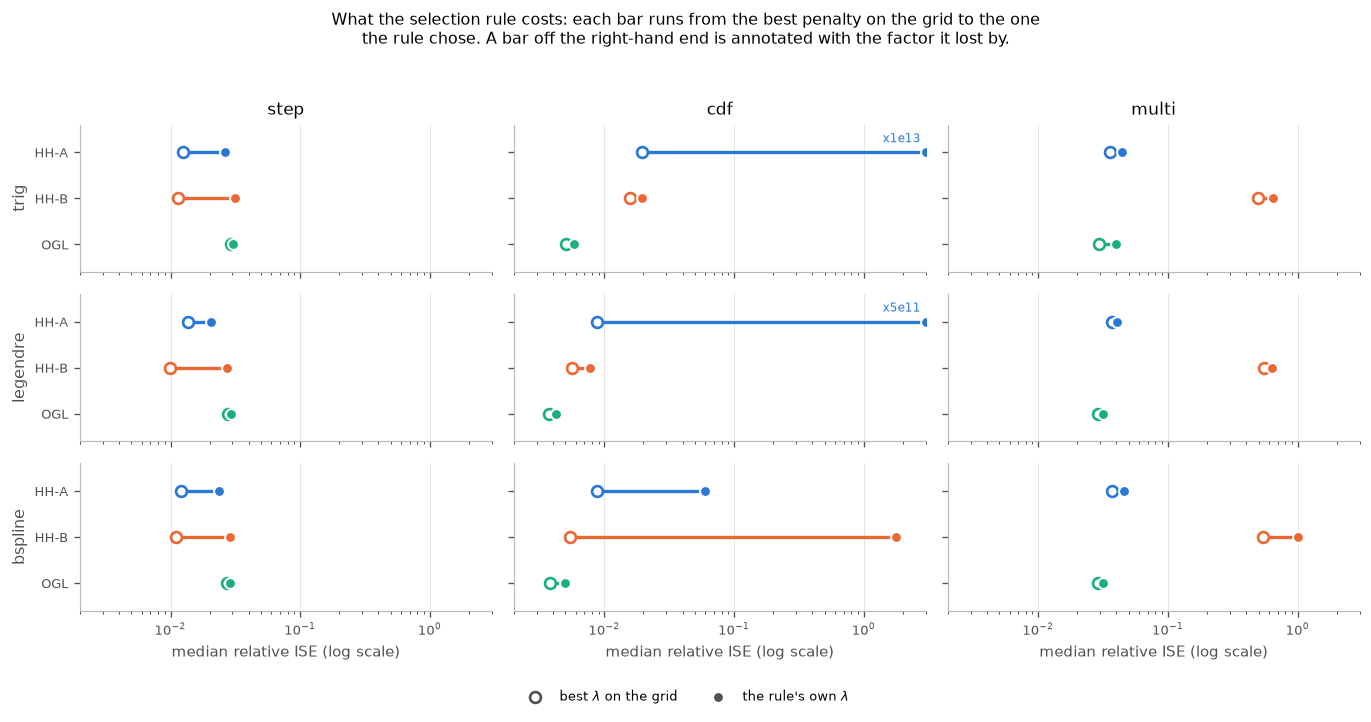

In [16]:
TUNABLE = ["HH-A", "HH-B", "OGL"]
med = pair.groupby(level=[0, 1, 3])[["rule", "oracle"]].median()

fig, ax = plt.subplots(3, 3, figsize=(11.5, 5.6), sharex=True, sharey=True)
for i, kind in enumerate(design.BASIS_KINDS):
    for j, target in enumerate(design.TARGETS):
        a = ax[i, j]
        for row, method in enumerate(TUNABLE):
            y = len(TUNABLE) - 1 - row
            rule_x, oracle_x = med.loc[(kind, target, method), ["rule", "oracle"]]
            a.plot([np.clip(oracle_x, XLO, XHI), np.clip(rule_x, XLO, XHI)], [y, y],
                   color=COLOUR[method], lw=2.0, solid_capstyle="butt", zorder=2)
            a.plot([np.clip(oracle_x, XLO, XHI)], [y], marker="o", ms=6.5,
                   color=style.SURFACE, mec=COLOUR[method], mew=1.6, zorder=3)
            a.plot([np.clip(rule_x, XLO, XHI)], [y], marker="o", ms=6.5,
                   color=COLOUR[method], mec="white", mew=1.2, zorder=4)
            if rule_x > XHI:
                a.annotate(f"x{style.fmt(rule_x / oracle_x)}", (XHI, y), xytext=(-3, 6),
                           textcoords="offset points", ha="right", fontsize=7,
                           color=COLOUR[method])
        a.set_xscale("log"); a.set_xlim(XLO, XHI)
        a.set_ylim(-0.6, len(TUNABLE) - 0.4)
        a.set_yticks(range(len(TUNABLE)))
        a.set_yticklabels(list(reversed(TUNABLE)))
        a.grid(axis="y", visible=False)
        if i == 0:
            a.set_title(target)
        if j == 0:
            a.set_ylabel(kind, fontsize=9.5)
        else:
            a.tick_params(labelleft=False)
        if i == 2:
            a.set_xlabel("median relative ISE (log scale)")
hollow = plt.Line2D([], [], marker="o", ls="none", ms=6.5, color=style.SURFACE,
                    mec=style.MUTED, mew=1.6, label=r"best $\lambda$ on the grid")
filled = plt.Line2D([], [], marker="o", ls="none", ms=6.5, color=style.MUTED,
                    mec="white", mew=1.2, label=r"the rule's own $\lambda$")
fig.legend(handles=[hollow, filled], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("What the selection rule costs: each bar runs from the best penalty on the "
             "grid to the one\nthe rule chose. A bar off the right-hand end is annotated "
             "with the factor it lost by.", fontsize=9.5, y=1.03)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

share of replications where section 3.2 chose the largest lambda on its grid
method           HH-A  HH-B
basis    target            
bspline  cdf     0.02  0.00
         multi   0.00  0.38
         step    0.00  0.00
legendre cdf     0.62  0.00
         multi   0.00  0.02
         step    0.00  0.00
trig     cdf     0.75  0.00
         multi   0.00  0.08
         step    0.00  0.00


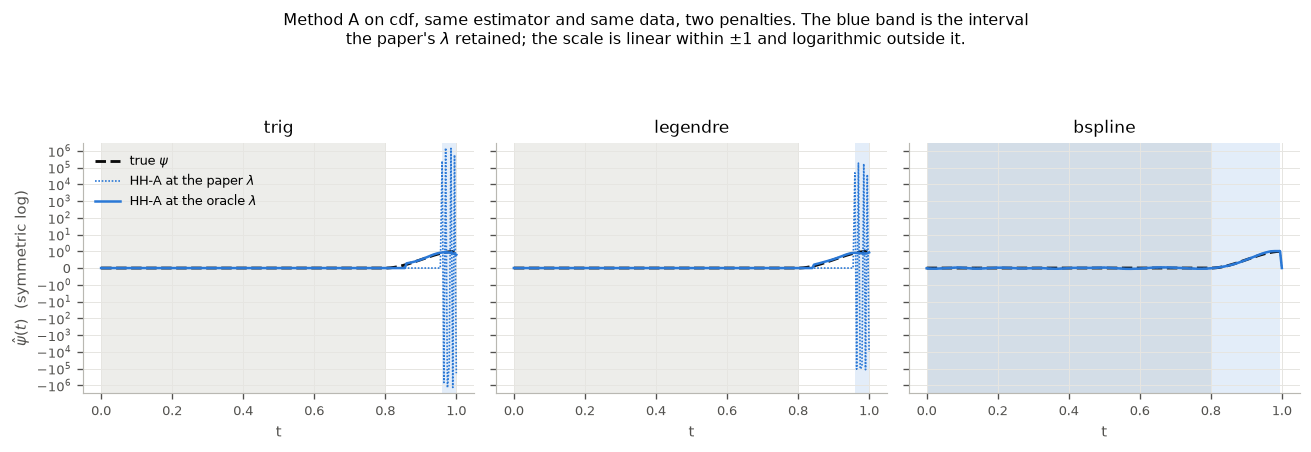

In [17]:
edge = paper[paper["bic_pick"]]
print("share of replications where section 3.2 chose the largest lambda on its grid")
print(edge.assign(top=edge["lam"] >= 0.99)
      .pivot_table(index=["basis", "target"], columns="method", values="top")
      .round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
psi = design.TARGETS["cdf"]["fn"](grid)
for a, kind in zip(ax, design.BASIS_KINDS):
    for lo, hi in SBC.find_regions(design.TARGETS["cdf"]["null"](grid), grid):
        a.axvspan(lo, hi, color=style.BAND, alpha=0.45, lw=0)
    a.plot(grid, psi, color=TRUTH, ls="--", lw=1.7, label=r"true $\psi$")
    for tuning, dash, width in (("paper", (0, (1, 1)), 1.0), ("oracle", None, 1.5)):
        sel = curves.query("basis == @kind and target == 'cdf' and method == 'HH-A' "
                           "and tuning == @tuning").sort_values("t")
        beta = sel["beta"].to_numpy()
        if tuning == "paper":
            for left, right in SBC.find_regions(beta != 0.0, grid):
                a.axvspan(left, right, color=COLOUR["HH-A"], alpha=0.13, lw=0)
        a.plot(sel["t"], beta, color=COLOUR["HH-A"], lw=width,
               ls="-" if dash is None else dash,
               label=f"HH-A at the {tuning} " + r"$\lambda$")
    a.set_yscale("symlog", linthresh=1.0, linscale=0.9)
    a.set_ylim(-3e6, 3e6)
    a.set_title(kind); a.set_xlabel("t")
ax[0].set_ylabel(r"$\hat\psi(t)$  (symmetric log)")
ax[0].legend(loc="upper left", fontsize=7.5)
fig.suptitle("Method A on cdf, same estimator and same data, two penalties. The blue band "
             "is the interval\nthe paper's $\\lambda$ retained; the scale is linear within "
             "$\\pm 1$ and logarithmic outside it.", fontsize=9.5, y=1.09)
plt.tight_layout(); plt.show()

This is the largest effect in the notebook, and it is not about the estimators.

Method A's collapse on `cdf` is a tuning failure rather than an estimation failure: at the best
$\lambda$ on its own grid it is an ordinary fit, within a factor of four of the best in the
cell. Section 3.2 chooses the largest $\lambda$ on the candidate grid on 62 and 75 per cent of
those replications; the penalty $n\lambda\theta^2$ then drives $\hat\theta$ to the far end of
the domain, leaving a retained interval of about four hundredths of the domain — some eight
grid points — and BIC fits as many components as that sub-grid can carry. That is the
near-singular truncated basis Hall & Hooker's Section 4 warns about, reached systematically
rather than by accident, and widening the grid does not rescue it: the criterion runs to
whatever ceiling it is given.

Method B's failures have the same cause on a different scale: on the B-spline `cdf` cell it is
239 times its own oracle. And at oracle $\lambda$ the `step` ordering reverses outright, method
B becoming the most accurate estimator in the study there — ahead of method A, and at less than
half the group lasso's error. The truncation model is not what loses those cells; the criterion
that tunes it is.

The group lasso's cross-validation, by contrast, costs between two and twenty-nine per cent. It
is close to the best $\lambda$ *for prediction error*, which is what it optimises, and it is the
same rule that returns no null set at all.

## Out-of-sample prediction

Recovering $\psi$ and predicting $y$ are different objectives, and cross-validation targets the
second. Five hundred fresh curves are drawn from each design and each fitted coefficient scored
on them, in units of $\sigma^2$, so $1.0$ is the noise floor no predictor can beat. Each
truncated fit is integrated over the sub-grid it was fitted on: integrating over the whole grid
with the coefficient zeroed past $\hat\theta$ straddles the jump with a trapezium panel and adds
a spurious half of $\hat b(\hat\theta) X(\hat\theta) h$.

In [18]:
print("median out-of-sample MSE, in units of sigma^2 (1.0 is the noise floor)")
print(cell_table(prescribed, "mse_test", "{:.3f}").to_string())

median out-of-sample MSE, in units of sigma^2 (1.0 is the noise floor)
method            HH-A    HH-B    OGL   FPCA
basis    target                             
bspline  cdf     1.194   1.085  1.093  1.128
         multi   1.134  13.441  1.188  1.506
         step    1.041   1.048  1.141  1.144
legendre cdf     1.147   1.021  1.098  1.125
         multi   1.155  13.998  1.238  1.620
         step    1.035   1.029  1.135  1.129
trig     cdf     1.269   1.049  1.110  1.505
         multi   1.158  12.300  1.184  1.622
         step    1.049   1.067  1.159  1.189


Prediction and recovery come apart, and in the more dangerous direction. Method A predicts
within thirty per cent of the noise floor on the very `cdf` cells where its coefficient function
is wrong by ten orders of magnitude: a wildly oscillating $\hat b$ on a sliver of retained
domain still integrates against $X$ to about the right number, because the sliver carries almost
no signal and the intercept absorbs the rest. Held-out error would have shown nothing amiss.

Method B on `multi` is the reverse, and the only entry here that predicts badly at all, at
twelve to fourteen times the noise floor — truncating to one window discards a bump whose
contribution to $y$ is real and opposite in sign. Its coefficient function is bad and its
predictions say so.

The lesson is not that held-out error is the wrong diagnostic but that it is not sufficient on
its own. Where the object of interest is $\psi$ rather than $y$, a method can sit near the noise
floor and still be useless.

## Are the gaps real

Every method saw the same data on every replication, so each contrast is paired and it is the
distribution of the *difference* that decides. We report medians and the Wilcoxon signed-rank
test rather than means and a $t$-test, for the reason Hall & Hooker's own Table 2 gives: method
A occasionally returns a wild estimate when BIC picks a large $m$ on a short retained interval,
and one such draw in forty makes a mean meaningless. $p$-values are Holm-corrected across the
nine cells within each contrast.

In [19]:
def holm(pvals):
    """Holm step-down adjustment of `pvals`, returned in the order given."""
    adj, running = np.empty(len(pvals)), 0.0
    for rank, idx in enumerate(np.argsort(pvals)):
        running = max(running, (len(pvals) - rank) * pvals[idx])
        adj[idx] = min(running, 1.0)
    return adj


wide = prescribed.pivot_table(index=["basis", "target", "rep"], columns="method",
                              values="rise")
rows = []
for a, b in [("OGL", "HH-A"), ("OGL", "HH-B"), ("HH-A", "HH-B")]:
    for (kind, target), cell in wide.groupby(level=[0, 1]):
        d = cell[a] - cell[b]
        rows.append({"contrast": f"{a} - {b}", "basis": kind, "target": target,
                     "median difference": float(np.median(d)),
                     "first wins": float(np.mean(d < 0)),
                     "p": float(wilcoxon(d).pvalue)})
tests = pd.DataFrame(rows)
tests["p (Holm)"] = np.concatenate(
    [holm(g["p"].to_numpy()) for _, g in tests.groupby("contrast", sort=False)])
for name, g in tests.groupby("contrast", sort=False):
    print(f"{name}   ('first wins' is the share of replications where {name[:4].strip()} "
          "has the lower error)")
    print(g.drop(columns="contrast").set_index(["basis", "target"])
          .assign(**{"median difference": lambda x: x["median difference"].map("{:.4g}".format)})
          .round({"first wins": 2, "p": 4, "p (Holm)": 4}).to_string())
    print()

OGL - HH-A   ('first wins' is the share of replications where OGL has the lower error)
                median difference  first wins       p  p (Holm)
basis    target                                                
bspline  cdf             -0.05633        1.00  0.0000    0.0000
         multi           -0.01119        0.70  0.0003    0.0007
         step             0.00772        0.22  0.0000    0.0001
legendre cdf           -4.624e+09        1.00  0.0000    0.0000
         multi          -0.008222        0.72  0.0001    0.0004
         step            0.008227        0.12  0.0000    0.0000
trig     cdf           -2.711e+11        1.00  0.0000    0.0000
         multi          0.0004314        0.50  0.4202    0.4202
         step            0.006594        0.25  0.0001    0.0004

OGL - HH-B   ('first wins' is the share of replications where OGL has the lower error)
                median difference  first wins       p  p (Holm)
basis    target                                          

## Failure modes and cost

A relative ISE of 1 or more means the estimate is no better than returning zero. Counting them
separates a method that is imprecise from one that occasionally falls over, and the two call
for different responses.

In [20]:
fail = (prescribed.assign(useless=prescribed["rise"] >= 1.0)
        .pivot_table(index=["basis", "target"], columns="method", values="useless",
                     aggfunc="sum"))
print(f"replications of {study.CONFIG['n_rep']} with relative ISE >= 1, "
      "i.e. no better than the zero estimate")
print(fail[[c for c in study.METHOD_ORDER if c in fail.columns]].astype(int).to_string())

worst = prescribed.loc[prescribed["rise"].idxmax()]
print()
print("the single worst fit in the study:")
print(worst[["basis", "target", "rep", "method", "orientation", "rise", "m", "lam",
             "null_measure", "mse_test"]].to_string())

print()
print("median seconds per fit (each orientation counted separately)")
print(df[df["tuning"].isin(study.PRESCRIBED)].groupby("method")["seconds"]
      .median().round(2).to_string())

replications of 40 with relative ISE >= 1, i.e. no better than the zero estimate
method           HH-A  HH-B  OGL  FPCA
basis    target                       
bspline  cdf        2    21    0     0
         multi      0    22    0     0
         step       0     0    0     0
legendre cdf       33     0    0     0
         multi      0    13    0     0
         step       0     0    0     0
trig     cdf       40     0    0     0
         multi      0    14    0     0
         step       0     0    0     0

the single worst fit in the study:
basis                          trig
target                          cdf
rep                              20
method                         HH-A
orientation                    left
rise            18914805355570940.0
m                              10.0
lam                             1.0
null_measure                 0.9475
mse_test                   1.450083

median seconds per fit (each orientation counted separately)
method
FPCA    0.00
HH-A    1.96

Both symptoms are in the fitted object. The worst fit in the study reports a null set covering
0.9475 of the domain, so it kept about eleven grid points, and fitted ten components on them —
the ceiling of its own BIC search. A retained interval that short together with a component
count at the ceiling is the signature, and neither half of it requires knowing the truth. That
is the difference between a method that fails and one that fails silently, and it is why Hall &
Hooker's Table 2 reports medians.

On cost, method B is the cheapest, method A a little over twice that — the separate principal
components analysis at every candidate endpoint, which the paper names as its price — and the
group lasso the most expensive, its ten-fold cross-validation over a thirty-penalty path
dominating. All three are seconds per fit, so cost is not what decides between them here.

## Summary

**Which model wins depends on the shape of $\psi$, not on the basis.** Method A has the lowest
median error on all three `step` cells; the group lasso on all three `cdf` cells and on two of
the three `multi` cells. That pattern is identical on Hall & Hooker's own trigonometric design,
on the group lasso's own B-spline design, and on the Legendre design belonging to neither.
Holding the covariance spectrum fixed and changing only the eigenfunctions moves the numbers,
sometimes substantially, and moves the ordering not at all. Whatever rule a practitioner should
use to choose between these methods, it is not "what do the curves look like".

**Most of the remaining margin is tuning, not estimation.** At the best $\lambda$ on its own
grid, method B is the most accurate estimator in the study on `step`, at less than half the
group lasso's error, and both truncation methods are respectable on `cdf`. Under section 3.2
they are not: the criterion costs method B a factor of 240 in one cell and method A more than
eleven orders of magnitude in two others, and it fails hardest where the boundary is smooth,
which the paper itself calls the harder case. Cross-validation costs the group lasso under
thirty per cent. The truncation model is in better shape than the numbers under its own tuning
rule suggest.

**The two literatures answer different questions.** Cross-validation returns a null set of
length zero on every replication, so the estimator with the best coefficient function reports
no null set at all under the rule its own paper prescribes. The one-standard-error rule
recovers one on the single-window targets for a small cost in error, and nothing recovers it on
`multi`, where the gap is narrower than the penalty's own groups. The truncation model returns
a null set by construction and, where it identifies the window, a very accurate endpoint.
Accuracy and support recovery are separate goods, and the same $\lambda$ does not buy both.

**Misspecification is not tuneable, but method A absorbs it better than method B.** On
`multi`, method B still costs about half the zero-estimate error at its oracle $\lambda$: no
penalty turns one interval into two. Method A is an order of magnitude better and wins every
paired replication against it, because re-estimating the coefficient inside the retained window
lets it fit a shape the frozen pilot cannot. That is the clearest case in this notebook for
method A over method B, and it is the case neither was designed for.

**And held-out error hides all of it.** Method A sits within thirty per cent of the noise floor
on the cells where its coefficient function is wrong by ten orders of magnitude.

**The practical reading**, now checked across three designs rather than one: fit the group
lasso first, since it costs little and assumes least, and read the null set off the
one-standard-error fit rather than the cross-validated one. If that null set is the complement
of a single interval, refit with the truncation model for an endpoint you can attach a sampling
distribution to — method A where the boundary looks like a jump, method B where it does not —
but tune it by something other than section 3.2, whose failure here is systematic rather than
occasional.